# Quantile Regression

## Alcance y pregunta

¿La heterocedasticidad cambia las pendientes de las colas aunque la media sea lineal?

**Laboratorio estructural sintético.** La ampliación semanal sustituye el baseline OLS genérico por un experimento del mecanismo anunciado. No contiene estimaciones de datos de Colombia ni evidencia de desempeño productivo.

## Modelo y mecanismo

$$Q_\tau(y\mid x)=a_\tau+b_\tau x$$

y=1+0.5x+(0.3+hx)ε con x uniforme positivo. Se estiman cuantiles 0.1 y 0.9 mediante LP con pérdida pinball y se contrasta con la pendiente poblacional 0.5+h Φ⁻¹(τ). Se añade la pendiente OLS de media.

### Supuestos de identificación

Errores normales independientes; escala siempre positiva; cuantil condicional lineal.

La verdad del DGP es conocida por construcción. Recuperar esa verdad comprueba implementación y diseño; no establece que el mecanismo describa una población observada.

## Configuración reproducible

Se usan NumPy, SciPy, Pandas y Matplotlib del entorno de investigación del repositorio. La semilla es fija, todos los cálculos se ejecutan desde los inputs y ninguna celda lee resultados precomputados. OLS incluye intercepto salvo fórmulas que lo excluyen explícitamente.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
plt.rcParams.update({'font.size': 11, 'axes.spines.top': False,
                     'axes.spines.right': False, 'figure.dpi': 110})
COLORS=['#245C83','#B56A20','#637843']
SEED=20261018
REPLICATIONS=40

def ols_fit(y, regressors):
    """Intercept included; QR/SVD-backed least squares, no matrix inversion."""
    X=np.column_stack([np.ones(len(y)),regressors])
    coefficients,_,rank,_=np.linalg.lstsq(X,y,rcond=None)
    if rank<X.shape[1]: raise ValueError('Diseño sin rango completo')
    return coefficients,y-X@coefficients

def ar_process(rng,n,rho):
    if abs(rho)>=1: raise ValueError('Se requiere AR estacionario')
    draws=rng.normal(size=n+200); x=np.zeros(n+200)
    for t in range(1,len(x)): x[t]=rho*x[t-1]+draws[t]
    return x[200:]


## Datos y experimento

y=1+0.5x+(0.3+hx)ε con x uniforme positivo. Se estiman cuantiles 0.1 y 0.9 mediante LP con pérdida pinball y se contrasta con la pendiente poblacional 0.5+h Φ⁻¹(τ). Se añade la pendiente OLS de media.

El siguiente código define el DGP o problema de equilibrio y sus comparadores. Las restricciones, oráculos analíticos y condiciones de factibilidad que corresponden al mecanismo se comprueban dentro de la función. Las cantidades monetarias se expresan en unidades sintéticas.

In [2]:
def experiment(rng,level,n=180):
    from scipy.optimize import linprog
    from scipy.stats import norm
    x=rng.uniform(0,2,n);y=1+.5*x+(.3+level*x)*rng.normal(size=n);X=np.c_[np.ones(n),x]
    values={}
    for quantile in [.1,.9]:
        objective=np.r_[np.zeros(2),np.full(n,quantile),np.full(n,1-quantile)]
        fit=linprog(objective,A_eq=np.c_[X,np.eye(n),-np.eye(n)],b_eq=y,bounds=[(None,None)]*2+[(0,None)]*(2*n),method='highs')
        assert fit.success
        values[f'Pendiente q{quantile}']=fit.x[1]
    values['Pendiente OLS']=ols_fit(y,x[:,None])[0][1]
    return values,(x,y)


### Un escenario reproducible

Cada métrica conserva su denominador y unidad conceptual; no se mezclan conteos, probabilidades y costos en un mismo eje. La tabla muestra el caso central de la malla, antes de resumir réplicas.

In [3]:
GRID=[0, 0.2, 0.4, 0.6, 0.8]
METRICS=['Pendiente q0.1', 'Pendiente q0.9', 'Pendiente OLS']
central=GRID[len(GRID)//2]
example,diagnostic=experiment(np.random.default_rng(SEED),central)
display(pd.DataFrame({'Métrica':list(example),'Valor':list(example.values())}))
print('Escenario central:',central,'; semilla:',SEED)


Escenario central: 0.4 ; semilla: 20261018


,Métrica,Valor
0,Pendiente q0.1,0.164746
1,Pendiente q0.9,1.061385
2,Pendiente OLS,0.532543


## Sensibilidad y variación entre réplicas

**Eje:** Heterocedasticidad h.

Se conservan 40 réplicas por escenario. Se reinicia la misma secuencia de semillas para cada nivel: las comparaciones entre niveles comparten innovaciones cuando la dimensión del DGP lo permite. En mecanismos deterministas los cuantiles coinciden; esto no representa una incertidumbre estimada de parámetros. No se descartan resultados desfavorables.

In [4]:
records=[]
for level in GRID:
    for replicate in range(REPLICATIONS):
        metrics,_=experiment(np.random.default_rng(SEED+replicate),level)
        if set(metrics)!=set(METRICS): raise AssertionError('Métricas inconsistentes')
        for name,value in metrics.items():
            if not np.isfinite(value):raise ArithmeticError(f'Resultado no finito: {name}')
            records.append({'nivel':level,'replica':replicate,'metrica':name,'valor':float(value)})
raw=pd.DataFrame(records)
summary=raw.groupby(['nivel','metrica'],sort=False).valor.agg(
    media='mean',mediana='median',sd_replicas='std',
    q025=lambda x:x.quantile(.025),q975=lambda x:x.quantile(.975),n='size').reset_index()
summary['se_media_mc']=summary.sd_replicas/np.sqrt(summary.n)
display(summary.round(5))


,nivel,metrica,media,mediana,sd_replicas,q025,q975,n,se_media_mc
0,0.0,Pendiente q0.1,0.51874,0.52426,0.07028,0.39719,0.64372,40,0.01111
1,0.0,Pendiente q0.9,0.50019,0.49700,0.06311,0.41263,0.62990,40,0.00998
2,0.0,Pendiente OLS,0.50010,0.49879,0.03736,0.43531,0.56159,40,0.00591
3,0.2,Pendiente q0.1,0.27240,0.28001,0.11936,0.03524,0.45438,40,0.01887
4,0.2,Pendiente q0.9,0.75075,0.74389,0.09173,0.58557,0.92077,40,0.01450
5,0.2,Pendiente OLS,0.49890,0.49192,0.06552,0.39751,0.61810,40,0.01036
6,0.4,Pendiente q0.1,0.02239,0.03829,0.16706,-0.27723,0.31838,40,0.02641
7,0.4,Pendiente q0.9,1.00070,0.99682,0.12334,0.77995,1.20240,40,0.01950
8,0.4,Pendiente OLS,0.49770,0.49777,0.09631,0.36578,0.67460,40,0.01523
9,0.6,Pendiente q0.1,-0.22694,-0.20009,0.21550,-0.58426,0.17046,40,0.03407


### Qué muestran los intervalos

Las bandas de la figura son cuantiles 2.5–97.5% entre realizaciones del DGP, **no intervalos de confianza de un estimador en una sola muestra**. `se_media_mc` mide únicamente el error Monte Carlo de la media en este conjunto de réplicas; no mide incertidumbre económica ni corrige especificación. Se informa media y mediana para detectar asimetría, especialmente bajo identificación débil.

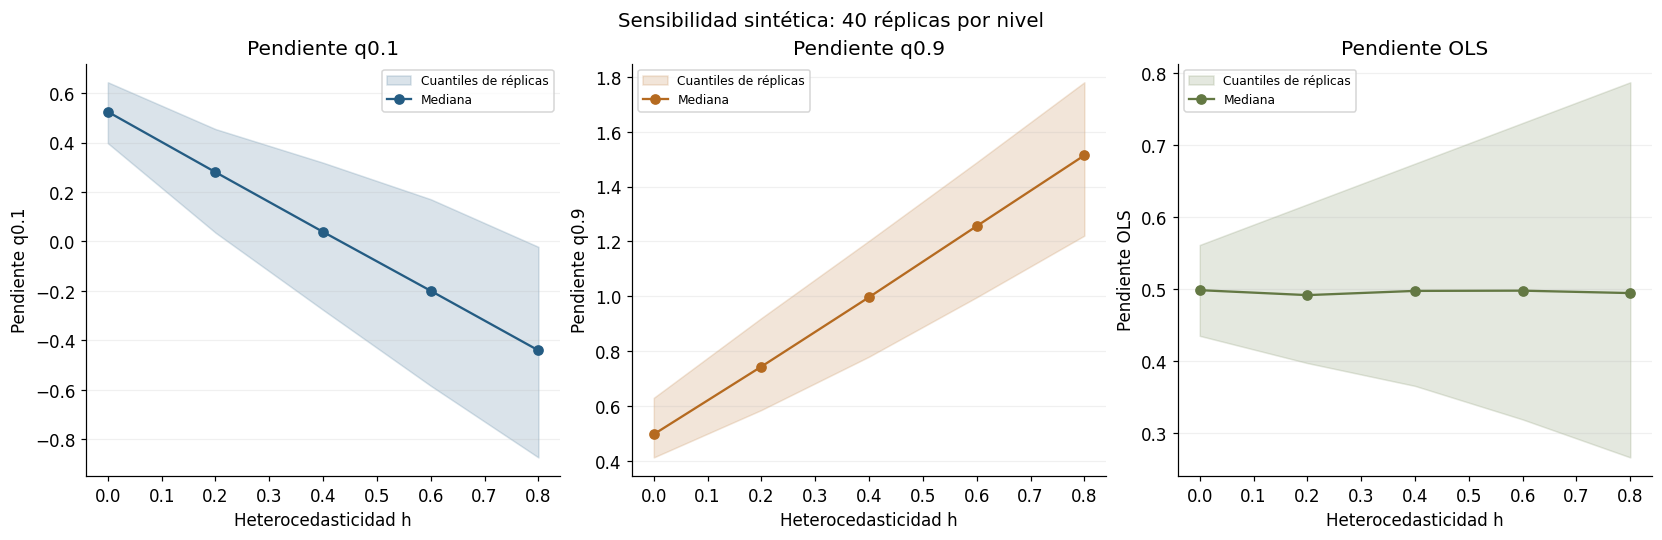

In [5]:
import textwrap
fig,axes=plt.subplots(1,len(METRICS),figsize=(15,4.8),layout='constrained')
for index,(ax,name) in enumerate(zip(np.atleast_1d(axes),METRICS)):
    group=summary[summary.metrica==name].sort_values('nivel')
    ax.fill_between(group.nivel,group.q025,group.q975,color=COLORS[index%3],alpha=.17,label='Cuantiles de réplicas')
    ax.plot(group.nivel,group.mediana,'o-',color=COLORS[index%3],label='Mediana')
    ax.set(title='\n'.join(textwrap.wrap(name,25)),xlabel='\n'.join(textwrap.wrap('Heterocedasticidad h',30)),ylabel=name)
    ax.grid(axis='y',alpha=.18); ax.legend(fontsize=8)
fig.suptitle('Sensibilidad sintética: 40 réplicas por nivel',fontsize=13)
plt.show()


## Lectura de resultados ejecutados

El contraste siguiente se calcula con las salidas de la ejecución, sin fijar de antemano el signo de la conclusión. Debe interpretarse junto con los supuestos y la variación entre réplicas.

In [6]:
for name in METRICS:
    group=summary[summary.metrica==name].sort_values('nivel')
    first,last=group.iloc[0],group.iloc[-1]
    print(f"{name}: mediana {first['mediana']:.6g} en nivel {first['nivel']:g}; "
          f"{last['mediana']:.6g} en nivel {last['nivel']:g}.")
    print(f"  Último escenario: cuantiles [{last['q025']:.6g}, {last['q975']:.6g}], "
          f"media {last['media']:.6g}, error MC de la media {last['se_media_mc']:.3g}.")


Pendiente q0.1: mediana 0.524263 en nivel 0; -0.440945 en nivel 0.8.
  Último escenario: cuantiles [-0.873973, -0.0221273], media -0.477504, error MC de la media 0.0411.
Pendiente q0.9: mediana 0.497005 en nivel 0; 1.51381 en nivel 0.8.
  Último escenario: cuantiles [1.22102, 1.78025], media 1.50202, error MC de la media 0.0294.
Pendiente OLS: mediana 0.498791 en nivel 0; 0.494738 en nivel 0.8.
  Último escenario: cuantiles [0.266411, 0.78762], media 0.495301, error MC de la media 0.0252.


## Comprobaciones y controles

La reproducibilidad exige que la misma semilla reconstruya las mismas métricas. Los asserts estructurales de la función no dependen de que un estimador estocástico gane a otro en esta realización. Los conteos se reconcilian para no perder réplicas silenciosamente.

In [7]:
repeated,_=experiment(np.random.default_rng(SEED),central)
assert all(np.isclose(example[k],repeated[k],rtol=0,atol=1e-12) for k in METRICS)
assert len(raw)==len(GRID)*REPLICATIONS*len(METRICS)
assert summary.n.eq(REPLICATIONS).all()
assert (summary.q025<=summary.mediana+1e-12).all()
assert (summary.mediana<=summary.q975+1e-12).all()
print('Semilla, finitud, cuantiles y totalidad de réplicas: correctos.')


Semilla, finitud, cuantiles y totalidad de réplicas: correctos.


## Límites y siguiente contraste

No se impone no cruce fuera del soporte y no se calibra riesgo extremo. Intervalos requieren un procedimiento de inferencia específico.

Antes de incorporar datos observados se debe fijar unidad de análisis, fecha de disponibilidad, reglas de exclusión y población de evaluación. La ampliación demuestra un mecanismo acotado; no convierte el proyecto en modelo validado externamente.

## Trazabilidad

Desarrollo semanal sobre `865c326`, revisión del 18-10-2026 UTC (noche del 17-10 en Colombia). El historial Git conserva el baseline genérico anterior. Todos los datos nuevos se regeneran desde la función `experiment`; las salidas del notebook se guardan después de ejecutar sus celdas de principio a fin.